# A/B 测试分析报告：网页版本实验

## 实验背景
- 对照组（Control）：**A 组**（旧版页面）
- 实验组（Treatment）：**B 组**（新版页面）
- 分流方式：用户按约 50/50 随机分流

> 命名约定：A 组为对照组，B 组为实验组；所有增量统一按 **实验组 B − 对照组 A** 计算。

## 指标定义

| 类型 | 指标 | 定义 |
| --- | --- | --- |
| 主指标 | 转化率 | 转化用户数 / 用户数(UV) |
| 辅助指标 | 浏览深度 | Page Views 总和 / UV |
| 辅助指标 | 平均停留时长 | Time Spent 总和 / UV |

## 统计假设
- H0：实验组与对照组转化率无差异
- H1：两组转化率存在差异（双尾检验，α = 0.05）

## 分析流程
1. 数据质量检查
2. 实验有效性校验（SRM 分流检验 + AA 协变量平衡检验）
3. 指标对比（增量 = 实验组 − 对照组）
4. 统计显著性检验与 95% 置信区间
5. 功效分析（样本量是否足够）
6. 分层分析（Device / Location）
7. 结论与建议


In [1]:
## 导入库与数据
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.proportion import (
    proportions_ztest,
    confint_proportions_2indep,
    proportion_confint,
    proportion_effectsize,
)
from statsmodels.stats.power import NormalIndPower

# 中文字体（Windows）
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei']
plt.rcParams['axes.unicode_minus'] = False

df = pd.read_csv('ab_testing.csv')
df.head()

,User ID,Group,Page Views,Time Spent,Conversion,Device,Location
0,14292,B,3,424,No,Mobile,Northern Ireland
1,11682,A,9,342,No,Mobile,Scotland
2,19825,A,2,396,No,Desktop,Northern Ireland
3,16080,B,4,318,No,Desktop,Wales
4,18851,A,1,338,Yes,Desktop,Scotland


In [2]:
## 数据质量检查
print(f'数据规模: {df.shape[0]} 行 x {df.shape[1]} 列')
print(f'缺失值总数: {df.isna().sum().sum()}')
print(f'完全重复行数: {df.duplicated().sum()}')
dup_uid = df['User ID'].duplicated().sum()
uniq_uid = df['User ID'].nunique()
print(f'User ID 重复行数: {dup_uid}')
print(f'User ID 唯一数: {uniq_uid}（与总行数一致说明每个用户仅一条记录）')
conv_dist = df['Conversion'].value_counts().to_dict()
print(f'Conversion 取值分布: {conv_dist}')

数据规模: 5000 行 x 7 列
缺失值总数: 0
完全重复行数: 0
User ID 重复行数: 0
User ID 唯一数: 5000（与总行数一致说明每个用户仅一条记录）
Conversion 取值分布: {'No': 4515, 'Yes': 485}


In [3]:
## 分组（A = 对照组 Control，B = 实验组 Treatment）
control = df[df['Group'] == 'A']
treatment = df[df['Group'] == 'B']

## 计算UV，PV
ctrl_uv = control['User ID'].nunique()
trt_uv = treatment['User ID'].nunique()
print(f'对照组(A) UV: {ctrl_uv}')
print(f'实验组(B) UV: {trt_uv}')

ctrl_pv = control['Page Views'].sum()
trt_pv = treatment['Page Views'].sum()
print(f'对照组(A) PV: {ctrl_pv}')
print(f'实验组(B) PV: {trt_pv}')

对照组(A) UV: 2519
实验组(B) UV: 2481
对照组(A) PV: 19098
实验组(B) PV: 18590


In [4]:
## 实验有效性校验 1：SRM 样本比例失配检验
observed = np.array([ctrl_uv, trt_uv])
expected = np.array([observed.sum() / 2] * 2)
chi2_srm, p_srm = stats.chisquare(observed, f_exp=expected)
print(f'SRM 卡方检验: chi2 = {chi2_srm:.4f}, p = {p_srm:.4f}')
print('分流比例健康' if p_srm > 0.05 else '警告：存在 SRM 问题，分流逻辑可能异常')

SRM 卡方检验: chi2 = 0.2888, p = 0.5910
分流比例健康


In [5]:
## 实验有效性校验 2：AA 平衡检验（协变量分布是否均衡）
for col in ['Device', 'Location']:
    table = pd.crosstab(df[col], df['Group'])
    chi2, p, dof, _ = stats.chi2_contingency(table)
    result = '均衡' if p > 0.05 else '不均衡，需排查'
    print(f'{col} 分布卡方检验: chi2 = {chi2:.4f}, p = {p:.4f} -> {result}')

Device 分布卡方检验: chi2 = 3.7318, p = 0.0534 -> 均衡
Location 分布卡方检验: chi2 = 4.1066, p = 0.2502 -> 均衡


In [6]:
## 行为指标对比（增量 = 实验组 B - 对照组 A）
### 浏览深度（定义：PV / UV）
ctrl_depth = ctrl_pv / ctrl_uv
trt_depth = trt_pv / trt_uv
print(f'对照组(A)浏览深度: {ctrl_depth:.3f}')
print(f'实验组(B)浏览深度: {trt_depth:.3f}')
print(f'实验组相对对照组提升: {trt_depth / ctrl_depth - 1:+.2%}')

### 平均停留时长（Time Spent / UV）
ctrl_time = control['Time Spent'].sum() / ctrl_uv
trt_time = treatment['Time Spent'].sum() / trt_uv
print(f'对照组(A)平均停留时长: {ctrl_time:.2f} 秒')
print(f'实验组(B)平均停留时长: {trt_time:.2f} 秒')
print(f'实验组相对对照组变化: {trt_time - ctrl_time:+.2f} 秒 ({trt_time / ctrl_time - 1:+.2%})')

### 转化率（Conversion == Yes 的用户数 / UV）
ctrl_conv = (control['Conversion'] == 'Yes').sum()
trt_conv = (treatment['Conversion'] == 'Yes').sum()
ctrl_cvr = ctrl_conv / ctrl_uv
trt_cvr = trt_conv / trt_uv
print(f'对照组(A)转化率: {ctrl_cvr:.4f} ({ctrl_conv}/{ctrl_uv})')
print(f'实验组(B)转化率: {trt_cvr:.4f} ({trt_conv}/{trt_uv})')
print(f'绝对提升(B-A): {trt_cvr - ctrl_cvr:+.4f}')
print(f'相对提升: {trt_cvr / ctrl_cvr - 1:+.2%}')

对照组(A)浏览深度: 7.582
实验组(B)浏览深度: 7.493
实验组相对对照组提升: -1.17%
对照组(A)平均停留时长: 241.73 秒
实验组(B)平均停留时长: 243.30 秒
实验组相对对照组变化: +1.57 秒 (+0.65%)
对照组(A)转化率: 0.0540 (136/2519)
实验组(B)转化率: 0.1407 (349/2481)
绝对提升(B-A): +0.0867
相对提升: +160.55%


In [7]:
## 统计显著性检验（α = 0.05，双尾）
alpha = 0.05

### 1. 转化率：双比例 z 检验 + 差异 95% 置信区间
count = np.array([trt_conv, ctrl_conv])
nobs = np.array([trt_uv, ctrl_uv])
z_stat, p_conv = proportions_ztest(count, nobs, alternative='two-sided')
ci_low, ci_high = confint_proportions_2indep(trt_conv, trt_uv, ctrl_conv, ctrl_uv, compare='diff', method='wald')
print(f'[转化率] 双比例 z 检验: z = {z_stat:.4f}, p = {p_conv:.4g}')
print(f'[转化率] 绝对提升 95% CI: [{ci_low:+.4f}, {ci_high:+.4f}]')
print('-> 差异显著' if p_conv < alpha else '-> 差异不显著')

### 2. 平均停留时长：Welch t 检验 + Mann-Whitney U 检验
t_stat, p_t = stats.ttest_ind(treatment['Time Spent'], control['Time Spent'], equal_var=False)
u_stat, p_u = stats.mannwhitneyu(treatment['Time Spent'], control['Time Spent'], alternative='two-sided')
print(f'[停留时长] Welch t 检验: t = {t_stat:.4f}, p = {p_t:.4g}')
print(f'[停留时长] Mann-Whitney U 检验: U = {u_stat:.0f}, p = {p_u:.4g}')

### 3. 浏览深度（每用户 Page Views）：Mann-Whitney U 检验
u_pv, p_pv = stats.mannwhitneyu(treatment['Page Views'], control['Page Views'], alternative='two-sided')
print(f'[浏览深度] Mann-Whitney U 检验: U = {u_pv:.0f}, p = {p_pv:.4g}')

[转化率] 双比例 z 检验: z = 10.3545, p = 3.993e-25
[转化率] 绝对提升 95% CI: [+0.0704, +0.1030]
-> 差异显著
[停留时长] Welch t 检验: t = 0.4695, p = 0.6387
[停留时长] Mann-Whitney U 检验: U = 3148544, p = 0.642
[浏览深度] Mann-Whitney U 检验: U = 3084181, p = 0.4247


In [8]:
## 功效分析：当前样本量是否足够
es = proportion_effectsize(trt_cvr, ctrl_cvr)
power = NormalIndPower().power(effect_size=es, nobs1=ctrl_uv, alpha=alpha, ratio=trt_uv / ctrl_uv)
print(f"观察到的效应量 Cohen's h: {es:.4f}")
print(f'当前样本量下的检验功效: {power:.4f}（> 0.8 视为充足）')

z_alpha = stats.norm.ppf(1 - alpha / 2)
z_beta = stats.norm.ppf(0.8)
mde_abs = (z_alpha + z_beta) * np.sqrt(2 * ctrl_cvr * (1 - ctrl_cvr) / ctrl_uv)
print(f'当前样本量在 80% 功效下可检出的最小绝对提升（近似）: {mde_abs:.4f}（{mde_abs:.2%}）')

观察到的效应量 Cohen's h: 0.2999
当前样本量下的检验功效: 1.0000（> 0.8 视为充足）
当前样本量在 80% 功效下可检出的最小绝对提升（近似）: 0.0178（1.78%）


In [9]:
## 分层分析：不同 Device / Location 下的转化率
converted = (df['Conversion'] == 'Yes').astype(int)
df_seg = df.assign(converted=converted)
for col in ['Device', 'Location']:
    seg = df_seg.pivot_table(index=col, columns='Group', values='converted', aggfunc='mean')
    seg = seg.rename(columns={'A': '对照组A', 'B': '实验组B'})
    seg['绝对提升(B-A)'] = seg['实验组B'] - seg['对照组A']
    print(f'按 {col} 分层的转化率:')
    print(seg.round(4))
    print()

按 Device 分层的转化率:
Group      对照组A    实验组B  绝对提升(B-A)
Device                            
Desktop  0.0587  0.1391     0.0804
Mobile   0.0494  0.1424     0.0930

按 Location 分层的转化率:
Group               对照组A    实验组B  绝对提升(B-A)
Location                                   
England           0.0693  0.1469     0.0776
Northern Ireland  0.0505  0.1146     0.0642
Scotland          0.0493  0.1506     0.1013
Wales             0.0477  0.1512     0.1035



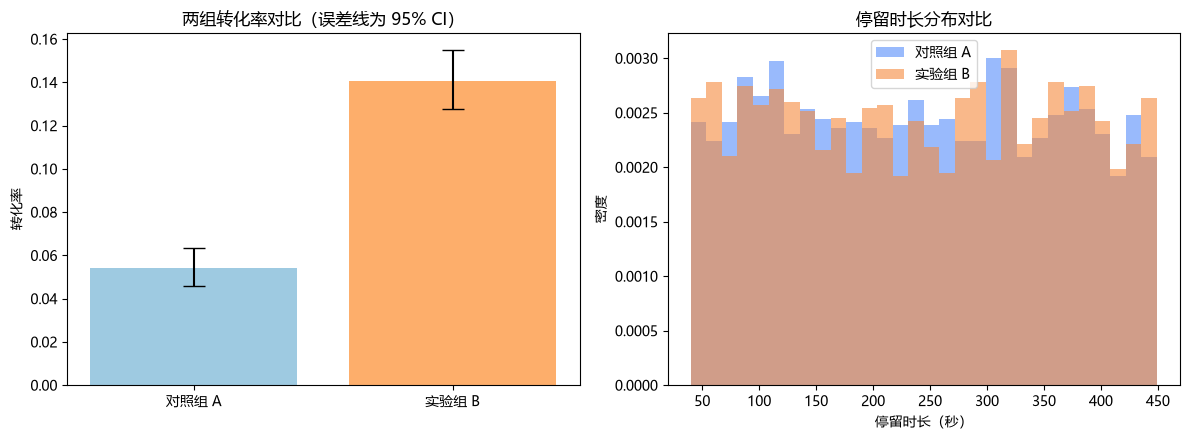

In [10]:
## 可视化
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

### 左图：两组转化率对比（含 95% 置信区间）
ctrl_ci = proportion_confint(ctrl_conv, ctrl_uv, alpha=alpha, method='wilson')
trt_ci = proportion_confint(trt_conv, trt_uv, alpha=alpha, method='wilson')
rates = [ctrl_cvr, trt_cvr]
err_low = [ctrl_cvr - ctrl_ci[0], trt_cvr - trt_ci[0]]
err_high = [ctrl_ci[1] - ctrl_cvr, trt_ci[1] - trt_cvr]
axes[0].bar(['对照组 A', '实验组 B'], rates, yerr=[err_low, err_high], capsize=8, color=['#9ecae1', '#fdae6b'])
axes[0].set_ylabel('转化率')
axes[0].set_title('两组转化率对比（误差线为 95% CI）')

### 右图：停留时长分布对比
axes[1].hist(control['Time Spent'], bins=30, alpha=0.6, label='对照组 A', density=True)
axes[1].hist(treatment['Time Spent'], bins=30, alpha=0.6, label='实验组 B', density=True)
axes[1].set_xlabel('停留时长（秒）')
axes[1].set_ylabel('密度')
axes[1].set_title('停留时长分布对比')
axes[1].legend()

plt.tight_layout()
plt.show()

## 结论与建议

### 一、实验有效性校验

| 校验项 | 结果 | 判定 |
| --- | --- | --- |
| 数据质量 | 5000 行数据、无缺失、无重复、每用户一条记录 | 通过 |
| SRM 分流检验 | chi2 = 0.2888, p = 0.591 | 分流比例健康，无样本比例失配 |
| AA 平衡检验 | Device p = 0.053、Location p = 0.250 | 协变量均衡，随机化有效 |

### 二、核心指标结论

| 指标 | 对照组 A | 实验组 B | 增量（B−A） | 检验方法 | p 值 | 结论 |
| --- | --- | --- | --- | --- | --- | --- |
| 转化率（主指标） | 5.40% | 14.07% | +8.67pp（相对 +160.6%） | 双比例 z 检验 | 3.99e-25 | 显著提升 |
| 平均停留时长 | 241.73 秒 | 243.30 秒 | +1.57 秒（+0.65%） | Welch t 检验 / Mann-Whitney U | 0.639 / 0.642 | 不显著 |
| 浏览深度 | 7.582 | 7.493 | -1.17% | Mann-Whitney U | 0.425 | 不显著 |

> 注：pp = 百分点（percentage point）；转化率绝对提升的 95% CI 为 [+7.04pp, +10.30pp]。

### 三、结论
1. 主指标显著提升：实验组转化率 14.07%，显著高于对照组 5.40%，绝对提升 +8.67pp，95% CI 完全在 0 之上（p = 3.99e-25）
2. 辅助指标无恶化：停留时长（+0.65%，p = 0.639）与浏览深度（-1.17%，p = 0.425）均无显著差异，转化提升并非以用户体验为代价
3. 分层结论一致：Desktop（+8.0pp）/ Mobile（+9.3pp）及各地区（+6.4pp ~ +10.4pp）子组均一致提升，无 Simpson 反转，结论稳健
4. 功效充足：检测该效应的统计功效约为 1.0；当前样本量在 80% 功效下可检出最小绝对提升约 1.78pp，观察到的效应远超该阈值

### 四、风险提示
1. 效应量异常大（相对提升 +160.6%），大幅超出常规实验水平，上线前建议复核：分流是否被污染、两组的转化口径/埋点是否一致
2. Device 平衡检验 p = 0.053 接近临界值，建议确认不同设备端的版本下发与统计口径无异常

### 五、行动建议
- 数据口径复核无误后：实验组版本可尽早灰度放量上线，并在放量后持续监控转化率与停留时长
- 若线上真实提升远小于实验数据，需按 MDE = 1.78pp 重新评估所需样本量
